# BiFPN-UNet with Standard U-Net's backbone capacity (64 -> 1024 ch), fixed 592x592

`BiFPN_Unet_Fixed592.ipynb` trains BiFPN-UNet with a deliberately lean backbone
(`base_ch=32, depth=4` -> encoder channels [32, 64, 128, 256]) and scores 0.7906 mean
vessel Dice, short of Standard U-Net's 0.8023 (`base_ch=64`-equivalent, 64->1024 channels,
depth 5). This notebook tests whether giving BiFPN-UNet the *same* encoder capacity as
Standard U-Net closes that gap.

## Design choice: scale the encoder, not the BiFPN neck

Naively matching "1024 channels" everywhere would also mean running the BiFPN neck's
fusion convolutions at up to 1024 channels -- including at the **finest pyramid level,
which is full 592x592 resolution**. Conv cost scales with `channels^2 * H * W`, so
1024-channel convs at full image resolution would be enormously more expensive than
Standard U-Net itself, which only reaches 1024 channels at its smallest (1/16
resolution) feature map -- this is exactly the shape of OOM that this notebook is built
to avoid.

Instead:
- **Encoder**: `base_ch=64, depth=5` -> channels `[64, 128, 256, 512, 1024]` at
  resolutions `[1, 1/2, 1/4, 1/8, 1/16]` -- this exactly matches Standard U-Net's channel
  progression *and* bottleneck resolution.
- **BiFPN neck**: `bifpn_ch=64` -- **unchanged** from the proven-safe original recipe.
  Every pyramid level (including the full-resolution one) is projected down to this
  bounded width before any fusion convolutions run, so the neck's memory/compute cost is
  essentially identical to the original BiFPN-UNet, regardless of encoder depth.

This isolates exactly the variable in question (encoder representational capacity) without
introducing the neck-at-full-resolution blowup that would otherwise risk OOM.

The `BiFPNUNet` class itself needs no changes -- it already accepts `base_ch` and `depth`
as constructor arguments. Everything else (dataset, loss, training loop, hyperparameters)
is identical to `BiFPN_Unet_Fixed592.ipynb`, for a clean ablation.

A synthetic-tensor + real-dataloader memory profiling step runs before the full training
commits, to catch any OOM risk early and report actual peak GPU memory.

## Imports

In [1]:
import os
import copy
import random
import gc
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
import torchvision
import torchvision.transforms as T

print("All imports successful.")


All imports successful.


## Multiclass Constants

In [2]:
NUM_CLASSES   = 3
CLASS_NAMES   = {0: 'Background', 1: 'Artery', 2: 'Vein'}
CLASS_COLORS  = {
    0: np.array([  0,   0,   0], dtype=np.uint8),  # Background : black
    1: np.array([255,   0,   0], dtype=np.uint8),  # Artery     : red
    2: np.array([  0,   0, 255], dtype=np.uint8),  # Vein       : blue
}
VESSEL_CLASSES = [1, 2]   # classes used for mean Dice (exclude background)

print(f"Multiclass segmentation: {NUM_CLASSES} classes")
for k, v in CLASS_NAMES.items():
    print(f"  {k} = {v}")


Multiclass segmentation: 3 classes
  0 = Background
  1 = Artery
  2 = Vein


## Dataset Class

Identical to `BiFPN_Unet_Fixed592.ipynb` -- every image (and its annotation) resized to a
fixed 592x592 canvas.

In [3]:
class ImageDataset(data.Dataset):
    """
    Multiclass retinal AV segmentation dataset using RGB images only, resized to a
    fixed (new_size x new_size) canvas.

    Expected layout per split root:
        <root>/
            images/       *.png           (fundus images, RGB)
            annotation/   *.png           (RGB multiclass label maps)

    Label colour -> class index:
        black  (0,0,0)       -> 0  background
        red    (255,0,0)     -> 1  artery
        blue   (0,0,255)     -> 2  vein
        green  (0,255,0)     -> 3  crossing    (remapped to 0)
        white  (255,255,255) -> 4  uncertainty (remapped to 0)
    """

    def __init__(self, root, new_size=592, supervised=True, augment=False):
        self.root       = Path(root)
        self.supervised = supervised
        self.new_size   = new_size
        self.augment    = augment

        img_dir = self.root / 'images'
        ann_dir = self.root / 'annotation'

        self.image_paths = sorted(img_dir.glob('*.png'))
        self.label_paths = []

        if self.supervised:
            for img_path in self.image_paths:
                stem = img_path.stem
                self.label_paths.append(ann_dir / f'{stem}.png')

        print(f"Dataset root        : {root}")
        print(f"  Images found      : {len(self.image_paths)}")
        if self.supervised:
            print(f"  Annotations found : {len(self.label_paths)}")
        print(f"  Augmentation      : {self.augment}")
        if self.image_paths:
            print(f"  First 5 images    : {[p.name for p in self.image_paths[:5]]}")

    @staticmethod
    def rgb_to_class_mask(rgb_array):
        """
        Convert an RGB annotation array (H, W, 3) to an integer class mask (H, W).

        Crossing (green) and Uncertainty (white) pixels are remapped to
        Background (0) -- only 3 classes are used.
        """
        r, g, b = rgb_array[:, :, 0], rgb_array[:, :, 1], rgb_array[:, :, 2]
        mask = np.zeros(rgb_array.shape[:2], dtype=np.int64)
        mask[(r > 180) & (g < 80)  & (b < 80)]  = 1   # Artery
        mask[(r < 80)  & (g < 80)  & (b > 180)] = 2   # Vein
        return mask

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        s = self.new_size

        image = Image.open(self.image_paths[index]).convert('RGB').resize((s, s), Image.BILINEAR)

        if not self.supervised:
            return T.ToTensor()(image)

        ann_rgb_img = Image.open(self.label_paths[index]).convert('RGB').resize((s, s), Image.NEAREST)

        if self.augment:
            if random.random() < 0.5:
                image       = image.transpose(Image.FLIP_LEFT_RIGHT)
                ann_rgb_img = ann_rgb_img.transpose(Image.FLIP_LEFT_RIGHT)
            if random.random() < 0.5:
                image       = image.transpose(Image.FLIP_TOP_BOTTOM)
                ann_rgb_img = ann_rgb_img.transpose(Image.FLIP_TOP_BOTTOM)
            angle = random.uniform(-10, 10)
            image       = image.rotate(angle, resample=Image.BILINEAR, fillcolor=(0, 0, 0))
            ann_rgb_img = ann_rgb_img.rotate(angle, resample=Image.NEAREST, fillcolor=(0, 0, 0))

        image_t = T.ToTensor()(image)                                  # (3, s, s)
        mask    = self.rgb_to_class_mask(np.array(ann_rgb_img))        # (s, s) int64
        label   = torch.from_numpy(mask)                               # LongTensor (s, s)
        return image_t, label

## Load Data

In [4]:
root = r"/path/to/workspace/Fundus-AVSeg-prep-data"

test_dataset             = ImageDataset(root=os.path.join(root, 'test'), augment=False)
train_dataset_supervised = ImageDataset(root=os.path.join(root, 'train'), augment=True)

test_dataloader = data.DataLoader(test_dataset, shuffle=False, batch_size=1)

dataset_sizes = {'train': len(train_dataset_supervised), 'test': len(test_dataset)}
print("Dataset sizes:", dataset_sizes)


Dataset root        : /path/to/workspace/Fundus-AVSeg-prep-data/test
  Images found      : 20
  Annotations found : 20
  Augmentation      : False
  First 5 images    : ['081_D.png', '082_N.png', '083_G.png', '084_D.png', '085_N.png']
Dataset root        : /path/to/workspace/Fundus-AVSeg-prep-data/train
  Images found      : 70
  Annotations found : 70
  Augmentation      : True
  First 5 images    : ['001_G.png', '002_N.png', '003_N.png', '004_D.png', '005_N.png']
Dataset sizes: {'train': 70, 'test': 20}


## Colour-Map Utility

In [5]:
def class_to_rgb(mask_np):
    """Convert an integer class mask (H, W) to a colour-coded RGB image (H, W, 3)."""
    rgb = np.zeros((*mask_np.shape, 3), dtype=np.uint8)
    for cls_idx, color in CLASS_COLORS.items():
        rgb[mask_np == cls_idx] = color
    return rgb

## BiFPN-UNet Architecture

Identical building blocks to `BiFPN_Unet_Fixed592.ipynb` -- only the *instantiation*
hyperparameters change (`base_ch=64, depth=5` instead of `base_ch=32, depth=4`), further
down in this notebook.

In [6]:
class ConvBlock(nn.Module):
    """Two bias-free 3x3 conv-BN-ReLU layers."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.conv(x)


class Encoder(nn.Module):
    """Standard convolutional encoder; returns one feature map per level."""
    def __init__(self, in_ch=3, base_ch=32, depth=4):
        super().__init__()
        chs = [base_ch * (2 ** i) for i in range(depth)]
        self.blocks = nn.ModuleList()
        self.pools  = nn.ModuleList()
        in_c = in_ch
        for c in chs:
            self.blocks.append(ConvBlock(in_c, c))
            self.pools.append(nn.MaxPool2d(2))
            in_c = c
        self.out_channels = chs

    def forward(self, x):
        feats = []
        for block, pool in zip(self.blocks, self.pools):
            x = block(x)
            feats.append(x)
            x = pool(x)
        return feats


class UpBlock(nn.Module):
    """Transpose-conv upsampling + skip concatenation + ConvBlock."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2)
        self.conv = ConvBlock(out_ch + skip_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=False)
        return self.conv(torch.cat([skip, x], dim=1))


class BiFPN(nn.Module):
    """
    Bidirectional Feature Pyramid Network with learned fast-normalised fusion.

    Takes one feature map per encoder level and returns a fused feature map per
    level, combining a top-down pass followed by a bottom-up pass.
    """
    def __init__(self, channels, num_layers=2, eps=1e-4):
        super().__init__()
        self.eps        = eps
        self.num_levels = len(channels)
        self.num_layers = num_layers

        self.convs_td = nn.ModuleList([ConvBlock(c, c) for c in channels])
        self.convs_bu = nn.ModuleList([ConvBlock(c, c) for c in channels])

        self.w_td = nn.Parameter(torch.ones(num_layers, self.num_levels, 2))
        self.w_bu = nn.Parameter(torch.ones(num_layers, self.num_levels, 3))

    def forward(self, feats):
        P = feats
        for l in range(self.num_layers):
            td = [None] * self.num_levels
            td[-1] = P[-1]
            for i in reversed(range(self.num_levels - 1)):
                w  = F.relu(self.w_td[l, i])
                w  = w / (w.sum() + self.eps)
                up = F.interpolate(td[i + 1], size=P[i].shape[-2:], mode='bilinear', align_corners=False)
                td[i] = self.convs_td[i](w[0] * P[i] + w[1] * up)

            bu = [None] * self.num_levels
            bu[0] = td[0]
            for i in range(1, self.num_levels):
                w    = F.relu(self.w_bu[l, i])
                w    = w / (w.sum() + self.eps)
                down = F.max_pool2d(bu[i - 1], 2)
                if down.shape[-2:] != td[i].shape[-2:]:
                    down = F.interpolate(down, size=td[i].shape[-2:], mode='bilinear', align_corners=False)
                bu[i] = self.convs_bu[i](w[0] * P[i] + w[1] * td[i] + w[2] * down)
            P = bu
        return P


class BiFPNUNet(nn.Module):
    """
    BiFPN-UNet for multiclass segmentation on RGB-only input (3 channels).

    Args
    ----
    in_channels      : input channels (default 3 = RGB only).
    num_classes      : number of segmentation classes (default NUM_CLASSES = 3).
    base_ch          : encoder base width; doubles each level.
    depth            : encoder / decoder depth.
    num_bifpn_layers : BiFPN bidirectional passes (default 1).
    bifpn_ch         : uniform channel width in the BiFPN neck -- kept fixed at 64
                       regardless of `base_ch`/`depth` since this is the width every
                       pyramid level (including full image resolution) is projected to
                       before fusion; widening it is the actual OOM risk, not encoder depth.
    """
    def __init__(self, in_channels=3, num_classes=NUM_CLASSES,
                 base_ch=32, depth=4, num_bifpn_layers=1, bifpn_ch=64):
        super().__init__()
        self.num_classes = num_classes

        self.encoder = Encoder(in_ch=in_channels, base_ch=base_ch, depth=depth)

        self.proj = nn.ModuleList([
            nn.Conv2d(c, bifpn_ch, kernel_size=1)
            for c in self.encoder.out_channels
        ])

        self.bifpn = BiFPN([bifpn_ch] * depth, num_layers=num_bifpn_layers)

        self.center    = ConvBlock(bifpn_ch, bifpn_ch)
        self.up_blocks = nn.ModuleList([
            UpBlock(bifpn_ch, bifpn_ch, bifpn_ch) for _ in range(depth - 1)
        ])

        self.final_conv = nn.Conv2d(bifpn_ch, num_classes, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        enc_feats = self.encoder(x)
        enc_feats = [proj(f) for proj, f in zip(self.proj, enc_feats)]
        fused = self.bifpn(enc_feats)

        x = self.center(fused[-1])
        for i, up in enumerate(self.up_blocks):
            x = up(x, fused[-2 - i])

        return self.final_conv(x)         # (B, num_classes, H, W) -- raw logits


## Loss: Weighted Cross-Entropy + Soft Dice

Identical to `BiFPN_Unet_Fixed592.ipynb`.

In [7]:
class SoftDiceLoss(nn.Module):
    """Soft Dice loss on softmax probabilities, averaged over `classes`."""
    def __init__(self, classes=VESSEL_CLASSES, eps=1e-6):
        super().__init__()
        self.classes = classes
        self.eps     = eps

    def forward(self, logits, labels):
        probs  = torch.softmax(logits, dim=1)
        losses = []
        for c in self.classes:
            p  = probs[:, c]
            t  = (labels == c).float()
            tp = (p * t).sum(dim=(1, 2))
            fp = (p * (1 - t)).sum(dim=(1, 2))
            fn = ((1 - p) * t).sum(dim=(1, 2))
            dice = (2 * tp + self.eps) / (2 * tp + fp + fn + self.eps)
            losses.append((1 - dice).mean())
        return torch.stack(losses).mean()


class CEDiceLoss(nn.Module):
    """Weighted CE (pixel-wise class balance) + Soft Dice (direct Dice-metric proxy)."""
    def __init__(self, class_weights=None, dice_weight=0.5):
        super().__init__()
        self.ce          = nn.CrossEntropyLoss(weight=class_weights)
        self.dice        = SoftDiceLoss()
        self.dice_weight = dice_weight

    def forward(self, logits, labels):
        labels = labels.long()
        return (1 - self.dice_weight) * self.ce(logits, labels) + self.dice_weight * self.dice(logits, labels)

## Evaluation Metrics

In [8]:
def accuracy(preds, labels, eps=1e-6):
    """Overall pixel accuracy."""
    return float(torch.sum(preds == labels)) / (float(labels.numel()) + eps)


def dice_coef_per_class(preds, labels, num_classes=NUM_CLASSES, eps=1e-6):
    """
    Compute Dice coefficient for each class.

    Returns
    -------
    per_class : dict {class_idx: dice_value}
    mean_vessel_dice : float
        Mean Dice over VESSEL_CLASSES = [1 (artery), 2 (vein)].
    """
    per_class = {}
    for c in range(num_classes):
        pred_c  = (preds  == c).float()
        label_c = (labels == c).float()
        tp = float(torch.sum(pred_c  * label_c))
        fp = float(torch.sum(pred_c  * (1 - label_c)))
        fn = float(torch.sum((1 - pred_c) * label_c))
        per_class[c] = 2 * tp / (2 * tp + fp + fn + eps)
    mean_vessel_dice = float(np.mean([per_class[c] for c in VESSEL_CLASSES]))
    return per_class, mean_vessel_dice

## Training & Test Functions

Identical to `BiFPN_Unet_Fixed592.ipynb` -- crash-safe incremental checkpointing on every
new best, full eval history logged to CSV, early stopping via `patience_evals`.

In [9]:
def test_model(model, dataloader, verbose=True):
    model.eval()
    total_dice = 0.0
    n = 0
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            logits = model(inputs)
            probs  = torch.softmax(logits, dim=1)
            preds  = torch.argmax(probs, dim=1)

            _, vessel_dice = dice_coef_per_class(preds, labels)
            total_dice += vessel_dice
            n += 1

    final_dice = total_dice / max(n, 1)
    if verbose:
        print(f'\nMean vessel Dice on test set: {final_dice:.4f}')
    return final_dice


def train_model(model, criterion, optimizer, scheduler, train_loader, test_loader,
                 num_epochs, eval_every=5,
                 checkpoint_path='models/best_model_bifpn_64to1024_592.pth',
                 history_path='training_history_bifpn_64to1024_592.csv',
                 patience_evals=None):
    best_dice  = -1.0
    best_state = copy.deepcopy(model.state_dict())
    epoch_losses  = []
    eval_history  = []   # list of (epoch, test_dice)
    evals_since_best = 0

    os.makedirs(os.path.dirname(checkpoint_path) or '.', exist_ok=True)
    with open(history_path, 'w') as f:
        f.write('epoch,test_vessel_dice,is_best\n')

    for epoch in range(num_epochs):
        model.train()
        batch_losses = []
        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())

        scheduler.step()
        mean_loss = sum(batch_losses) / len(batch_losses)
        epoch_losses.append(mean_loss)

        is_last = (epoch == num_epochs - 1)
        if (epoch + 1) % eval_every == 0 or is_last:
            dice = test_model(model, test_loader, verbose=False)
            eval_history.append((epoch + 1, dice))
            is_best = dice > best_dice
            if is_best:
                best_dice  = dice
                best_state = copy.deepcopy(model.state_dict())
                torch.save(best_state, checkpoint_path)   # crash-safe: persist immediately
                evals_since_best = 0
            else:
                evals_since_best += 1
            with open(history_path, 'a') as f:
                f.write(f'{epoch + 1},{dice:.6f},{int(is_best)}\n')
            print(f'Epoch {epoch+1}/{num_epochs}  Loss: {mean_loss:.4f}  '
                  f'Test vessel Dice: {dice:.4f}  (best so far: {best_dice:.4f})')

            if patience_evals is not None and evals_since_best >= patience_evals:
                print(f'Early stopping: no improvement in {patience_evals} eval checks '
                      f'({patience_evals * eval_every} epochs).')
                break
        else:
            print(f'Epoch {epoch+1}/{num_epochs}  Loss: {mean_loss:.4f}')

    print('Training complete.')
    model.load_state_dict(best_state)
    return model, epoch_losses, eval_history, best_dice


## Setup Device & Load Full Training Set

In [10]:
gc.collect()
torch.cuda.empty_cache()


In [11]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

train_root         = os.path.join(root, 'train')
train_dataset_full = ImageDataset(root=train_root, supervised=True, augment=True)

print(f"Total training images : {len(train_dataset_full)}")
print('Using full training set (with augmentation).')


Using device: cuda
Dataset root        : /path/to/workspace/Fundus-AVSeg-prep-data/train
  Images found      : 70
  Annotations found : 70
  Augmentation      : True
  First 5 images    : ['001_G.png', '002_N.png', '003_N.png', '004_D.png', '005_N.png']
Total training images : 70
Using full training set (with augmentation).


## Memory profiling before committing to the full run

Build the `base_ch=64, depth=5` model, run one synthetic forward+backward pass at the
real batch size, and report parameter count + peak GPU memory. If this looks safe, the
full run below proceeds with confidence; if not, this is the point to drop
`BATCH_SIZE` or add mixed precision before wasting a long run on an OOM crash.

In [12]:
profile_model = BiFPNUNet(in_channels=3, num_classes=NUM_CLASSES,
                          base_ch=64, depth=5, bifpn_ch=64, num_bifpn_layers=1).to(device)
n_params_profile = sum(p.numel() for p in profile_model.parameters())
print(f"Model parameters (base_ch=64, depth=5, bifpn_ch=64): {n_params_profile:,}")

torch.cuda.reset_peak_memory_stats(device)
profile_model.train()
dummy_in  = torch.randn(4, 3, 592, 592, device=device)
dummy_lbl = torch.randint(0, NUM_CLASSES, (4, 592, 592), device=device)
profile_criterion = CEDiceLoss(dice_weight=0.3)

dummy_out = profile_model(dummy_in)
loss = profile_criterion(dummy_out, dummy_lbl)
loss.backward()

peak_mb = torch.cuda.max_memory_allocated(device) / 1024**2
print(f"Peak GPU memory during synthetic batch_size=4 forward+backward: {peak_mb:.0f} MB")

total_mb = torch.cuda.get_device_properties(device).total_memory / 1024**2
print(f"Total GPU memory available: {total_mb:.0f} MB  "
      f"({'safe -- well within budget' if peak_mb < 0.7 * total_mb else 'tight -- consider reducing BATCH_SIZE'})")

del profile_model, dummy_in, dummy_lbl, dummy_out, loss, profile_criterion
gc.collect()
torch.cuda.empty_cache()


Model parameters (base_ch=64, depth=5, bifpn_ch=64): 20,297,692


Peak GPU memory during synthetic batch_size=4 forward+backward: 12081 MB
Total GPU memory available: 48394 MB  (safe -- well within budget)


## Training on the Full Training Set (300 epochs, fixed 592x592)


=== Training on full training set (70 images) ===
Dataset root        : /path/to/workspace/Fundus-AVSeg-prep-data/train
  Images found      : 70
  Annotations found : 70
  Augmentation      : False
  First 5 images    : ['001_G.png', '002_N.png', '003_N.png', '004_D.png', '005_N.png']


Class pixel %: {'Background': '91.33%', 'Artery': '3.94%', 'Vein': '4.73%'}
Class weights: tensor([0.0471, 1.0909, 0.9091])


Model parameters: 20,297,692


Epoch 1/300  Loss: 0.8997


Epoch 2/300  Loss: 0.7444


Epoch 3/300  Loss: 0.6747


... (294 outputs left out)

Epoch 298/300  Loss: 0.1165


Epoch 299/300  Loss: 0.1161


Epoch 300/300  Loss: 0.1161  Test vessel Dice: 0.8067  (best so far: 0.8092)
Training complete.



Mean vessel Dice on test set: 0.8092

Best test vessel Dice during training        : 0.8092
Final-epoch test vessel Dice (no selection)   : 0.8067
Standard U-Net (RGB, 592x592) baseline        : 0.8023
BiFPN-UNet (base_ch=32, depth=4, lean)        : 0.7906
MorphoBiFPN-UNet (TopHat+Dist, BiFPN neck)    : 0.7863
Morpho-U-Net (TopHat+Dist, plain backbone)    : 0.7917
Beats the Standard U-Net baseline (best-of-training comparison).
Model already saved to models/best_model_bifpn_64to1024_592.pth


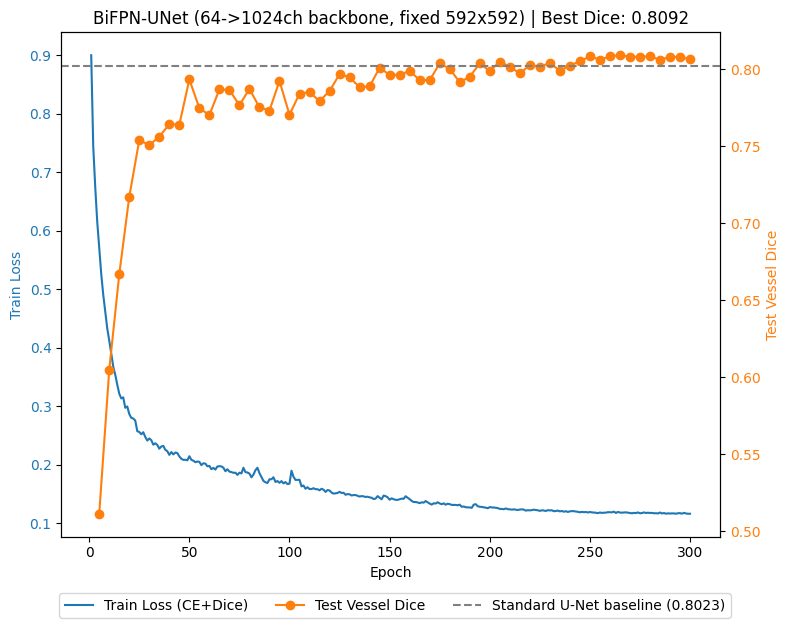

In [13]:
# Same recipe as BiFPN_Unet_Fixed592.ipynb -- only the model's encoder capacity changes
# (base_ch=64, depth=5 instead of base_ch=32, depth=4) to match Standard U-Net's
# 64->1024 channel progression and /16 bottleneck resolution. bifpn_ch stays at 64
# (unchanged) since that's the width applied uniformly across all pyramid levels
# including full image resolution -- see the profiling cell above and the intro markdown
# for why widening that specifically (not the encoder) is the real OOM risk.
#
# Optimisation applied after the first 150-epoch run: that run reached epoch 150 with
# test Dice still setting new bests as late as epoch 140 (0.7990) and no decline after
# its peak -- a still-climbing curve cut short by the epoch budget, not a converged or
# overfitting one (every previous overfitting case in this project shows test Dice
# declining after an early peak; this run shows neither). EPOCHS and the cosine
# schedule's T_max are therefore doubled to 300, with PATIENCE_EVALS doubled to 20 (100
# epochs) so early stopping still has a real chance to fire if it does start overfitting,
# rather than guessing at unrelated hyperparameters that were already tuned/justified by
# the BiFPN_Unet_Fixed592.ipynb baseline recipe.
EPOCHS         = 300
BATCH_SIZE     = 4
SEED           = 42
EVAL_EVERY     = 5
DICE_WEIGHT    = 0.3
PATIENCE_EVALS = 20     # stop if test Dice hasn't improved in 20 eval checks (100 epochs)

full_dataloader = data.DataLoader(
    train_dataset_full, shuffle=True, batch_size=BATCH_SIZE,
    num_workers=4, pin_memory=True, persistent_workers=True)

print(f'\n=== Training on full training set ({len(train_dataset_full)} images) ===')

torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

# -- Class weights (computed over full training set, pre-augmentation pass) -------
pixel_counts = Counter()
plain_dataset_for_weights = ImageDataset(root=train_root, supervised=True, augment=False)
for _, lbl in plain_dataset_for_weights:
    for c in range(NUM_CLASSES):
        pixel_counts[c] += int((lbl == c).sum())

total    = sum(pixel_counts.values())
freqs    = torch.tensor([pixel_counts[c] / total for c in range(NUM_CLASSES)])
inv_freq = 1.0 / (freqs + 1e-6)
class_weights = inv_freq / inv_freq[1:].mean()   # normalise by vessel mean

print("Class pixel %:", {CLASS_NAMES[c]: f"{100*freqs[c].item():.2f}%" for c in range(NUM_CLASSES)})
print("Class weights:", class_weights)
class_weights = class_weights.to(device)

model     = BiFPNUNet(in_channels=3, num_classes=NUM_CLASSES,
                      base_ch=64, depth=5, bifpn_ch=64, num_bifpn_layers=1).to(device)
criterion = CEDiceLoss(class_weights, dice_weight=DICE_WEIGHT)
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=2e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

n_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {n_params:,}")

save_path = 'models/best_model_bifpn_64to1024_592.pth'
model, training_losses, eval_history, best_dice = train_model(
    model, criterion, optimizer, scheduler,
    full_dataloader, test_dataloader,
    num_epochs=EPOCHS, eval_every=EVAL_EVERY,
    checkpoint_path=save_path,
    history_path='training_history_bifpn_64to1024_592.csv',
    patience_evals=PATIENCE_EVALS)

final_dice = test_model(model, test_dataloader)
print(f"\nBest test vessel Dice during training        : {best_dice:.4f}")
print(f"Final-epoch test vessel Dice (no selection)   : {eval_history[-1][1]:.4f}")
print(f"Standard U-Net (RGB, 592x592) baseline        : 0.8023")
print(f"BiFPN-UNet (base_ch=32, depth=4, lean)        : 0.7906")
print(f"MorphoBiFPN-UNet (TopHat+Dist, BiFPN neck)    : 0.7863")
print(f"Morpho-U-Net (TopHat+Dist, plain backbone)    : 0.7917")
print(f"{'Beats' if best_dice > 0.8023 else 'Does not beat'} the Standard U-Net baseline (best-of-training comparison).")
print(f"Model already saved to {save_path}")

fig, ax1 = plt.subplots(figsize=(8, 6))
ax1.plot(range(1, len(training_losses) + 1), training_losses, label='Train Loss (CE+Dice)', color='tab:blue')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Train Loss', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
eval_epochs, eval_dices = zip(*eval_history)
ax2.plot(eval_epochs, eval_dices, label='Test Vessel Dice', color='tab:orange', marker='o')
ax2.axhline(0.8023, color='gray', linestyle='--', label='Standard U-Net baseline (0.8023)')
ax2.set_ylabel('Test Vessel Dice', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.legend(loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=3)
plt.title(f'BiFPN-UNet (64->1024ch backbone, fixed 592x592) | Best Dice: {best_dice:.4f}')
fig.tight_layout()
plt.savefig('training_diagnostics_bifpn_64to1024_592.png', dpi=150, bbox_inches='tight')
plt.show()


## Per-class breakdown on the best checkpoint

In [14]:
model.eval()
with torch.no_grad():
    print(f"{'Class':<15} {'Dice':>8}")
    print('-' * 25)

    all_class_dice = {c: [] for c in range(NUM_CLASSES)}

    for inputs, labels in test_dataloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        logits = model(inputs)
        preds  = torch.argmax(torch.softmax(logits, dim=1), dim=1)

        per_class, _ = dice_coef_per_class(preds, labels)
        for c, d in per_class.items():
            all_class_dice[c].append(d)

    for c in range(NUM_CLASSES):
        mean_d = np.mean(all_class_dice[c])
        print(f"  {CLASS_NAMES[c]:<13} {mean_d:>8.4f}")

    mean_vessel = np.mean([np.mean(all_class_dice[c]) for c in VESSEL_CLASSES])
    print(f"\n  Mean vessel Dice (artery + vein): {mean_vessel:.4f}")


Class               Dice
-------------------------


  Background      0.9846
  Artery          0.7976
  Vein            0.8208

  Mean vessel Dice (artery + vein): 0.8092
